<a href="https://colab.research.google.com/github/PierreCr/Computational-Pathology/blob/main/Miniproject2.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Mini-project in Computational Pathology - Tissue mask and detection; H&E stain deconvolution; nucleus segmentation.
# Pierre Cordier, DVM, PhD, Dipl.ECVP.
# 24/10/2026.


In [1]:
# Mount Google Drive
from google.colab import drive
drive.mount("/content/drive/")

Mounted at /content/drive/


In [3]:
# Import packages
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image
from pathlib import Path

Array shape: (1000, 1000, 3)
Pixel range: 0 to 255


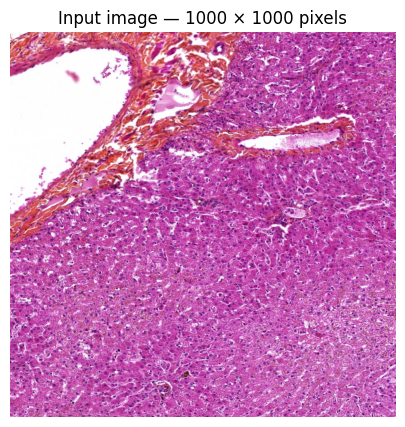

In [153]:
# I - Load and inspect the image
IMAGE_PATH = Path("/content/drive/MyDrive/WSI_LHA0912-24/LHA0912_patches1024x1024/LHA0912_patch_295.png")
image_pil = Image.open(IMAGE_PATH).convert("RGB")

MAX_SIDE = 2500
scale = min(1.0, MAX_SIDE / max(image_pil.size))

if scale < 1.0:
  new_size = (round(image_pil.width * scale), round(image_pil.height * scale))
  image_pil = image_pil.resize(new_size, Image.Resampling.LANCZOS)

rgb = np.asarray(image_pil)
height, width = rgb.shape[:2]
print("Array shape:", rgb.shape)
print("Pixel range:", rgb.min(), "to", rgb.max())

plt.figure(figsize=(7, 5))
plt.imshow(rgb)
plt.title(f"Input image — {width} × {height} pixels")
plt.axis("off")
plt.show()

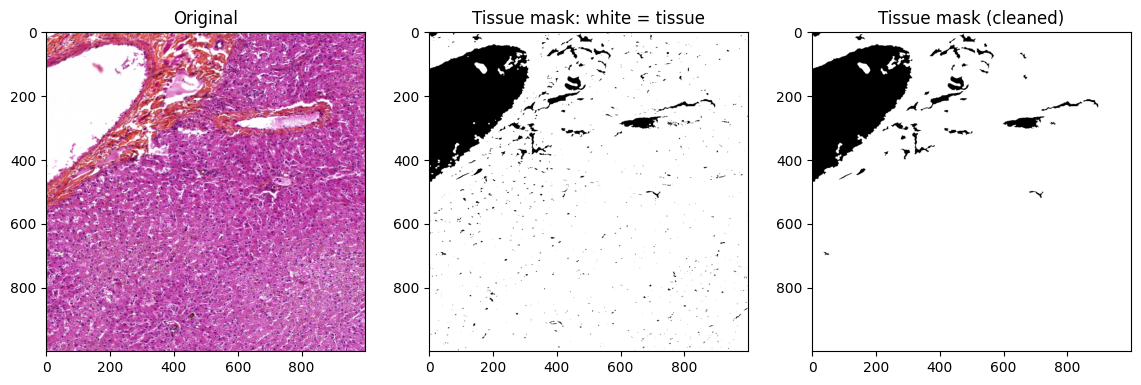

Estimated tissue coverage: 89.8%
Estimated tissue coverage after cleaning: 90.5%


In [154]:
# II - Detect tissue and estimate tissue coverage #1st method
from skimage.color import rgb2hsv
from skimage.morphology import remove_small_objects, remove_small_holes

# Mask based on saturation
hsv = rgb2hsv(rgb.astype(np.float32) / 255.0)
saturation = hsv[:, :, 1]
TISSUE_SATURATION_THRESHOLD = 0.08 # Try 0.05, 0.08, 0.12
tissue_mask = saturation > TISSUE_SATURATION_THRESHOLD

# Optional cleanup
mask_clean = remove_small_objects(tissue_mask, min_size=64)
mask_clean = remove_small_holes(mask_clean, area_threshold=64)

# Plotting
fig, axes = plt.subplots(1, 3, figsize=(14, 5))
axes[0].imshow(rgb); axes[0].set_title("Original")
axes[1].imshow(tissue_mask, cmap="gray") ; axes[1].set_title("Tissue mask: white = tissue")
axes[2].imshow(mask_clean, cmap="gray"); axes[2].set_title("Tissue mask (cleaned)")
plt.show()

# Tissue coverage
tissue_coverage = 100 * tissue_mask.mean()
tissue_coverage_cleaned = 100 * mask_clean.mean()
print(f"Estimated tissue coverage: {tissue_coverage:.1f}%")
print(f"Estimated tissue coverage after cleaning: {tissue_coverage_cleaned:.1f}%")

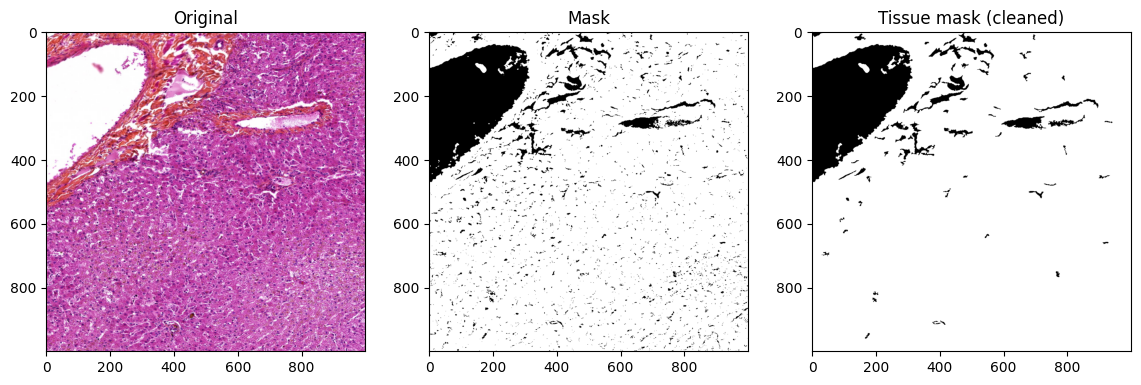

Estimated tissue coverage: 87.5%
Estimated tissue coverage after cleaning: 89.5%


In [155]:
# II - Detect tissue and estimate tissue coverage #2nd method
from skimage.color import rgb2hsv
from skimage.morphology import remove_small_objects, remove_small_holes

# Mask based on Green channel
gray = rgb[:, :, 1]
tissue_mask = gray < 200

# Optional cleanup
mask_clean = remove_small_objects(tissue_mask, min_size=64)
mask_clean = remove_small_holes(mask_clean, area_threshold=64)

# Plotting
fig, axes = plt.subplots(1, 3, figsize=(14, 5))
axes[0].imshow(rgb); axes[0].set_title("Original")
axes[1].imshow(tissue_mask, cmap="gray"); axes[1].set_title("Mask")
axes[2].imshow(mask_clean, cmap="gray"); axes[2].set_title("Tissue mask (cleaned)")
plt.show()

# Tissue coverage
tissue_coverage = 100 * tissue_mask.mean()
tissue_coverage_cleaned = 100 * mask_clean.mean()
print(f"Estimated tissue coverage: {tissue_coverage:.1f}%")
print(f"Estimated tissue coverage after cleaning: {tissue_coverage_cleaned:.1f}%")

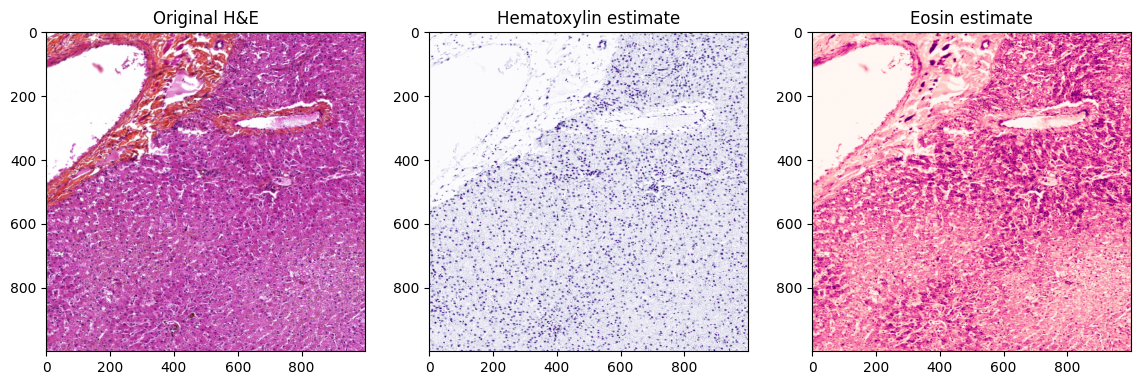

In [157]:
# III - Approximate H&E stain separation
from skimage.color import rgb2hed
from skimage.exposure import rescale_intensity

# Color deconvolution in the HE(D) colorspace
hed = rgb2hed(rgb)
hematoxylin = hed[:, :, 0]
eosin = hed[:, :, 1]

# Rescaling intensity (for plotting)
val_min_h, val_max_h = np.percentile(hematoxylin, (1, 99))
hematoxylin_rescaled = rescale_intensity(hematoxylin, in_range=(val_min_h, val_max_h), out_range=(0, 1))

val_min_e, val_max_e = np.percentile(eosin, (1, 99))
eosin_rescaled = rescale_intensity(eosin, in_range=(val_min_e, val_max_e), out_range=(0, 1))

# Plotting
fig, axes = plt.subplots(1, 3, figsize=(14, 5))
axes[0].imshow(rgb); axes[0].set_title("Original H&E")
axes[1].imshow(hematoxylin_rescaled, cmap="Purples"); axes[1].set_title("Hematoxylin estimate")
axes[2].imshow(eosin_rescaled, cmap="RdPu"); axes[2].set_title("Eosin estimate")
plt.show()

1. H&E color deconvolution.

La fonction rgb2hed de skimage retourne des valeurs d'intensité de couleur décomposées (dans l'espace HED) qui sont généralement très petites (souvent proches de 0, avec certaines valeurs négatives ou légèrement supérieures). En les affichant directement avec plt.imshow en échelle de gris sans normalisation ou sans carte de couleurs appropriée, la dynamique visuelle est extrêmement faible, ce qui donne cette impression d'image presque entièrement noire. Pour mieux visualiser l'intensité de chaque colorant, nous pouvons normaliser ou étirer le contraste des canaux d'hématoxyline et d'éosine avec rescale_intensity.

2. Rescaling.

Le choix du 99ème percentile (au lieu du maximum absolu à 100 %) pour définir val_max est une technique standard de traitement d'images médicales et de microscopie pour les raisons suivantes :

* Robustesse face au bruit (Outliers) : Dans les images de lames histologiques (WSI), il y a souvent des pixels extrêmement brillants isolés, de la poussière, des artefacts de numérisation ou des reflets de lumière. Si on utilisait le maximum absolu (100%), la présence d'un seul pixel aberrant très intense forcerait toute la plage dynamique à s'ajuster sur lui, rendant le reste de l'image très sombre.

* Amélioration du contraste : En ignorant les 1 % des pixels les plus extrêmes (les plus clairs et les plus sombres avec le 1er et 99ème percentile), on sature légèrement ces quelques pixels aberrants pour étirer de manière optimale la dynamique des 98 % restants. Cela offre un contraste visuel bien plus net et utile pour l'analyse.

En résumé, le 99ème percentile permet d'avoir une échelle d'intensité représentative de la vraie distribution des couleurs des tissus (hématoxyline/éosine) plutôt que des anomalies de l'image.

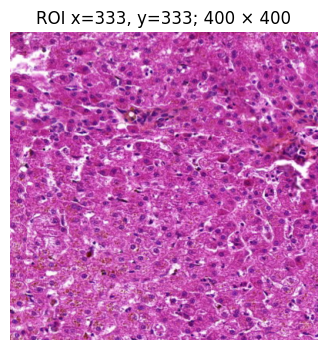

In [165]:
# IV - Exploratory nuclei detection in a region of interest.

# Adjust after viewing the original image
ROI_X = width // 3
ROI_Y = height // 3
ROI_SIZE = 400

x0 = max(0, min(ROI_X, width - 1))
y0 = max(0, min(ROI_Y, height - 1))
x1 = min(width, x0 + ROI_SIZE)
y1 = min(height, y0 + ROI_SIZE)

roi_rgb = rgb[y0:y1, x0:x1]
roi_mask = mask_clean[y0:y1, x0:x1]
roi_h = hematoxylin[y0:y1, x0:x1]

plt.figure(figsize=(4, 4))
plt.imshow(roi_rgb)
plt.title(f"ROI x={x0}, y={y0}; {x1-x0} × {y1-y0}")
plt.axis("off"); plt.show()


In [162]:
# Nucleus segmentation
from skimage.filters import threshold_otsu
from skimage.morphology import remove_small_objects, disk, opening
from skimage.segmentation import watershed
from scipy import ndimage as ndi

h_values = roi_h[roi_mask]
if h_values.size < 50:
   ValueError("Too little tissue in ROI. Choose a different region.")

h_threshold = threshold_otsu(h_values)
nuclear_candidates = (roi_h > h_threshold) & roi_mask
nuclear_candidates = remove_small_objects(nuclear_candidates, min_size=8)
nuclear_candidates = opening(nuclear_candidates, disk(1))

distance = ndi.distance_transform_edt(nuclear_candidates)
local_max = distance == ndi.maximum_filter(distance, size=5)
markers, _ = ndi.label(local_max & nuclear_candidates)

labels = watershed(-distance, markers, mask=nuclear_candidates)
counts = np.bincount(labels.ravel())
keep = np.zeros(counts.shape, dtype=bool)
keep[counts > 10] = True
keep[0] = False
labels_filtered = keep[labels]

nuclei_count = int(np.unique(labels_filtered[labels_filtered > 0]).size)
print("Otsu threshold:", round(float(h_threshold), 4))
print("Candidate segments:", nuclei_count)

Otsu threshold: 0.033
Candidate segments: 1


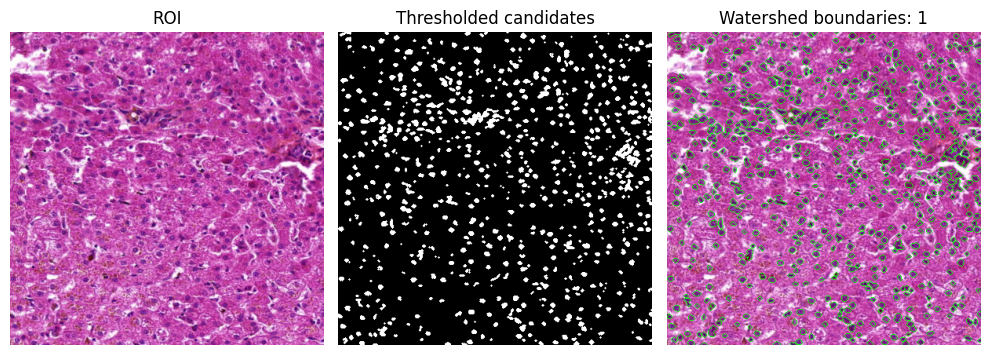

In [171]:
# Display segmented nuclei
from skimage.segmentation import find_boundaries

boundaries = find_boundaries(labels_filtered, mode="outer")
overlay = roi_rgb.copy()
overlay[boundaries] = [0, 255, 0]

fig, axes = plt.subplots(1, 3, figsize=(10, 5))
axes[0].imshow(roi_rgb); axes[0].set_title("ROI")
axes[1].imshow(nuclear_candidates, cmap="gray")
axes[1].set_title("Thresholded candidates")
axes[2].imshow(overlay)
axes[2].set_title(f"Watershed boundaries: {nuclei_count}")
for ax in axes: ax.axis("off")
plt.tight_layout(); plt.show()